In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

from test_cases import build_test_suite
from Chern import ChernovSolver
from solvers import FiniteDifferenceSolver, RungeKuttaSolver, RosenbrockSolver
from mc_solver import solve as mc_solve

tasks = {tc.name: tc for tc in build_test_suite()}

N = 320            # число шагов метода Ремизова (Ричардсон по N и N/2)
DX_GRID = 0.005    # шаг сеточных методов
MC_M, MC_DT = 20_000, 0.002   # параметры Монте-Карло
RESULTS = {}

In [2]:
def remizov(tc, p):
    def run(n, T=None):
        s = ChernovSolver(tc.a, tc.b, tc.c, tc.g, tc.lam,
                          tc.x_min - p["margin"], tc.x_max + p["margin"], p["dx"],
                          T=T, n=n, num_t=p["num_t"], eps=p["eps"])
        return s.x_grid, s.solve(n_jobs=-1), s.T
    x, half, T = run(N // 2)
    _, full, _ = run(N, T)
    return x, 2 * full - half


def grid_method(cls, tc):
    lo, hi = tc.x_min, tc.x_max
    bc_l = ("dirichlet", float(tc.f_exact(np.array([lo]))[0]))
    bc_r = ("dirichlet", float(tc.f_exact(np.array([hi]))[0]))
    s = cls(tc.a, tc.b, tc.c, tc.g, tc.lam, lo, hi, DX_GRID,
            bc_left=bc_l, bc_right=bc_r)
    return s.x_grid, s.solve()


def sup_err(tc, x, f):
    m = (x >= tc.x_min - 1e-12) & (x <= tc.x_max + 1e-12)
    return float(np.max(np.abs(f[m] - tc.f_exact(x[m]))))

In [ ]:
def show_results(tc, res, curves, r):
    print(f"{'метод':20s} {'погрешность':>12s} {'время, с':>9s}")
    for k, (e, t) in res.items():
        print(f"{k:20s} {e:12.2e} {t:9.2f}")

    fig, ax = plt.subplots(figsize=(8, 3.2))
    xs = np.linspace(-1, 1, 801)
    ax.plot(xs, tc.f_exact(xs), color="0.2", lw=2.5, alpha=0.4, label="точное")
    for k, st in (("метод Ремизова", "-"), ("конечные разности", "--")):
        x, f = curves[k]
        m = (x >= -1) & (x <= 1)
        ax.plot(x[m], f[m], st, lw=1, label=k)
    ax.errorbar([0.0], [r.value], yerr=[r.ci95], fmt="s", mfc="none",
                capsize=3, color="tab:red", label="Монте-Карло ± 95%")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 1. `const_baseline`

Чистая диффузия, гауссов колокол, базовая сверка с ядром резольвенты exp(-sqrt(lam)|x-y|)/(2 sqrt(lam)).

$$
a(x)=1,\qquad b(x)=0,\qquad c(x)=0,\qquad \lambda=2.
$$

$$
f_*(x)=e^{- 4 x^{2}}.
$$


метод                 погрешность  время, с
метод Ремизова           1.83e-05      2.67
конечные разности        1.50e-05      0.00
Рунге–Кутта 4            7.85e-11      0.02
Розенброк 2              1.08e-05      0.04
Монте-Карло (x=0)        7.50e-03      1.07
Монте-Карло: f(0) ≈ 0.9925 ± 0.0106


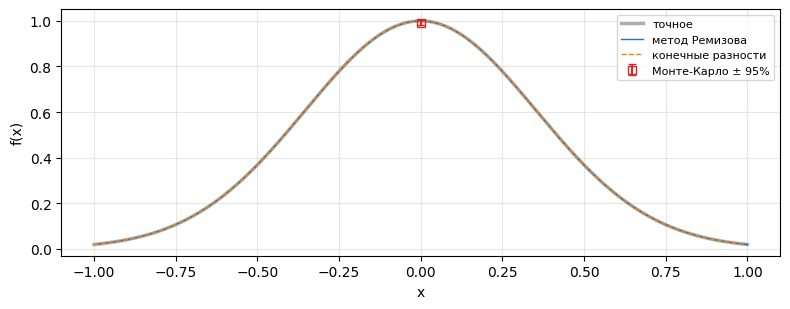

In [4]:
tc = tasks["const_baseline"]
p = {'dx': 0.01, 'num_t': 201, 'eps': 0.0001, 'margin': 2.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 2. `const_convection`

Диффузия + снос + реакция, немонотонное решение.

$$
a(x)=1,\qquad b(x)=\frac{3}{2},\qquad c(x)=\frac{1}{2},\qquad \lambda=3.
$$

$$
f_*(x)=e^{- 2 x^{2}} \cos{\left(2 x \right)}.
$$



метод                 погрешность  время, с
метод Ремизова           5.08e-06      7.20
конечные разности        1.80e-05      0.00
Рунге–Кутта 4            1.60e-10      0.03
Розенброк 2              9.90e-06      0.05
Монте-Карло (x=0)        5.95e-03      3.87
Монте-Карло: f(0) ≈ 1.0059 ± 0.0101


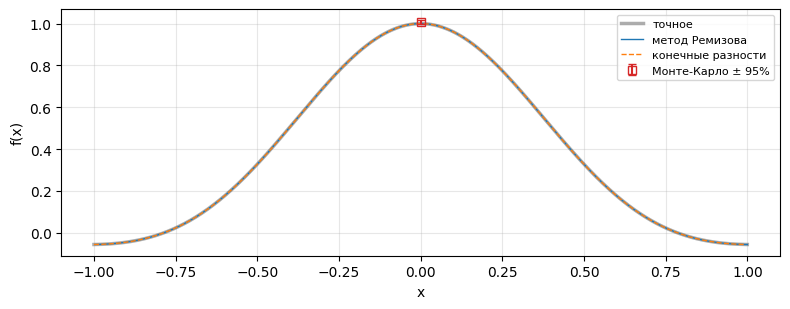

In [5]:
tc = tasks["const_convection"]
p = {'dx': 0.005, 'num_t': 401, 'eps': 0.0001, 'margin': 2.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 3. `var_smooth`

a(x) in [0.7,1.3] — гладкая, но не постоянная эллиптичность. c(x)=0.3*tanh(x): похоже на 0.3*x вблизи 0 (тот же характер на [-1,1]), но ограничено на R (|c|<=0.3 всюду) — требование a,b,c in UC_b(R) из task.md.

$$
a(x)=\frac{3 \sin{\left(\pi x \right)}}{10} + 1,\qquad b(x)=\frac{2 \cos{\left(\pi x \right)}}{5},\qquad c(x)=\frac{3 \tanh{\left(x \right)}}{10},\qquad \lambda=\frac{3}{2}.
$$

$$
f_*(x)=e^{- 3 x^{2}} \sin{\left(2 x \right)}.
$$



метод                 погрешность  время, с
метод Ремизова           2.45e-05      7.59
конечные разности        1.69e-05      0.00
Рунге–Кутта 4            1.62e-10      0.04
Розенброк 2              1.14e-05      0.05
Монте-Карло (x=0)        4.69e-03     14.76
Монте-Карло: f(0) ≈ 0.0047 ± 0.0123


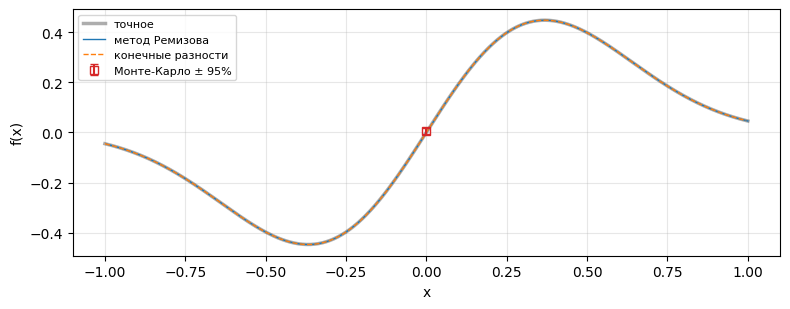

In [6]:
tc = tasks["var_smooth"]
p = {'dx': 0.005, 'num_t': 401, 'eps': 0.0001, 'margin': 3.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 4. `var_pinch`

a(x) in [0.1,0.9] — заметное сужение эллиптичности внутри окна. b(x)=0.2*tanh(x) вместо 0.2*x — ограничено на R.

$$
a(x)=\frac{2 \cos{\left(2 \pi x \right)}}{5} + \frac{1}{2},\qquad b(x)=\frac{\tanh{\left(x \right)}}{5},\qquad c(x)=0,\qquad \lambda=1.
$$

$$
f_*(x)=e^{- x^{2}} \cos{\left(3 x \right)}.
$$



метод                 погрешность  время, с
метод Ремизова           1.44e-04      7.40
конечные разности        2.78e-05      0.00
Рунге–Кутта 4            2.71e-10      0.03
Розенброк 2              1.42e-05      0.05
Монте-Карло (x=0)        3.26e-03     15.16
Монте-Карло: f(0) ≈ 1.0033 ± 0.0138


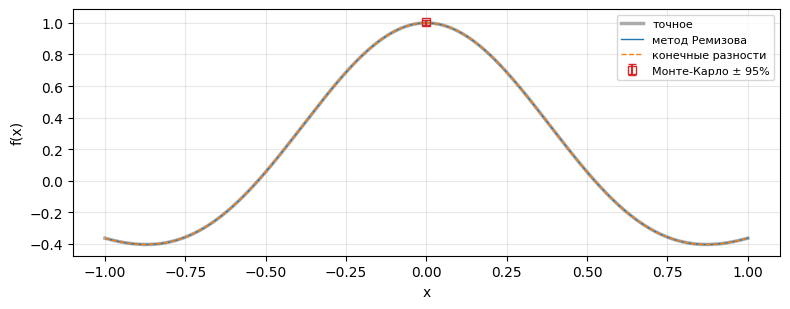

In [7]:
tc = tasks["var_pinch"]
p = {'dx': 0.005, 'num_t': 401, 'eps': 0.0001, 'margin': 2.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 5. `stiff_const`

a/b = 0.005 — то же решение, что const_baseline, но жёсткий оператор: RK4 должен требовать заметно мельче шаг, чем FD/Rosenbrock.

$$
a(x)=\frac{1}{100},\qquad b(x)=2,\qquad c(x)=0,\qquad \lambda=1.
$$

$$
f_*(x)=e^{- 4 x^{2}}.
$$


метод                 погрешность  время, с
метод Ремизова           3.17e-05      1.57
конечные разности        3.51e-05      0.00
Рунге–Кутта 4            7.76e-08      0.02
Розенброк 2              5.69e-06      0.05
Монте-Карло (x=0)        2.93e-04      3.82
Монте-Карло: f(0) ≈ 1.0003 ± 0.0013


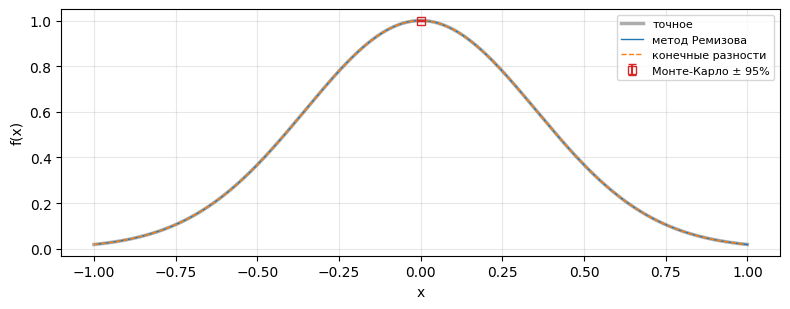

In [8]:
tc = tasks["stiff_const"]
p = {'dx': 0.01, 'num_t': 101, 'eps': 0.001, 'margin': 2.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 6. `stiff_variable`

a(x) in [0.01,0.03], b(x) in [2,4] — жёсткость меняется вдоль x.

$$
a(x)=\frac{\cos{\left(\pi x \right)}}{100} + \frac{1}{50},\qquad b(x)=\sin{\left(\pi x \right)} + 3,\qquad c(x)=0,\qquad \lambda=1.
$$

$$
f_*(x)=e^{- 2 x^{2}} \cos{\left(4 x \right)}.
$$



метод                 погрешность  время, с
метод Ремизова           6.83e-05      1.42
конечные разности        7.30e-05      0.00
Рунге–Кутта 4            1.60e-07      0.04
Розенброк 2              2.02e-05      0.06
Монте-Карло (x=0)        1.64e-03     17.48
Монте-Карло: f(0) ≈ 1.0016 ± 0.0029


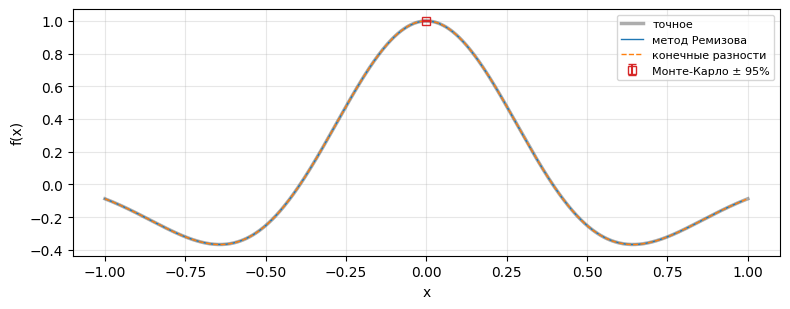

In [9]:
tc = tasks["stiff_variable"]
p = {'dx': 0.02, 'num_t': 101, 'eps': 0.001, 'margin': 2.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 7. `osc_highfreq_solution`

Высокочастотное решение — проверка требований к dx.

$$
a(x)=1,\qquad b(x)=0,\qquad c(x)=0,\qquad \lambda=5.
$$

$$
f_*(x)=e^{- x^{2}} \cos{\left(15 x \right)}.
$$



метод                 погрешность  время, с
метод Ремизова           1.83e-06     20.02
конечные разности        4.96e-04      0.00
Рунге–Кутта 4            3.30e-08      0.02
Розенброк 2              3.73e-04      0.05
Монте-Карло (x=0)        1.84e-02      1.42
Монте-Карло: f(0) ≈ 0.9816 ± 0.0584


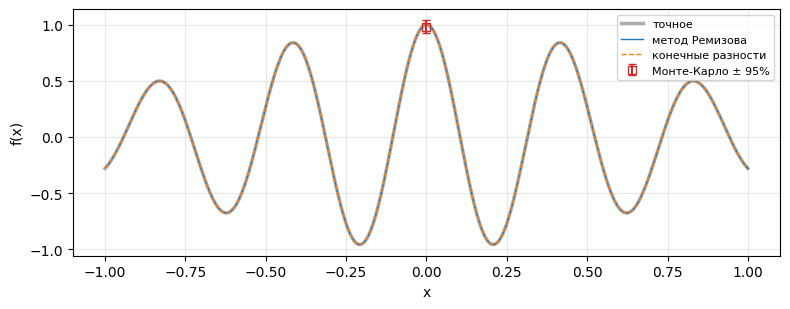

In [10]:
tc = tasks["osc_highfreq_solution"]
p = {'dx': 0.0025, 'num_t': 801, 'eps': 0.001, 'margin': 3.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 8. `osc_coefficient`

Осциллирующий c(x), sup|c|=4 близко к lam=5 (delta=1) — чувствительность к оценке ||c||_inf и к T.

$$
a(x)=1,\qquad b(x)=0,\qquad c(x)=4 \sin{\left(10 x \right)},\qquad \lambda=5.
$$

$$
f_*(x)=e^{- 2 x^{2}}.
$$



метод                 погрешность  время, с
метод Ремизова           4.69e-05      2.99
конечные разности        5.65e-06      0.00
Рунге–Кутта 4            5.17e-11      0.02
Розенброк 2              3.42e-06      0.05
Монте-Карло (x=0)        4.01e-04      5.54
Монте-Карло: f(0) ≈ 1.0004 ± 0.0048


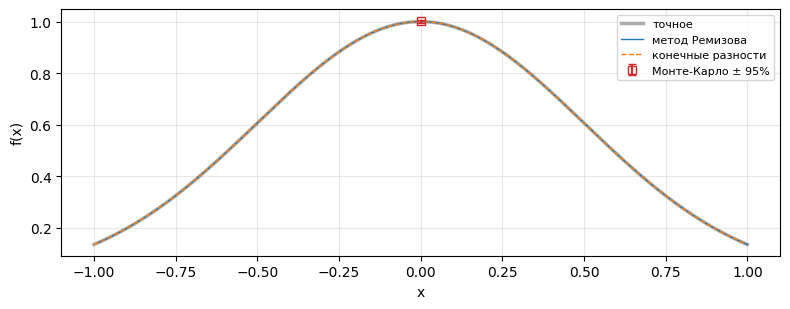

In [11]:
tc = tasks["osc_coefficient"]
p = {'dx': 0.01, 'num_t': 201, 'eps': 0.001, 'margin': 2.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 9. `glued_smooth`

При x<=0: exp(-x^2). При x>=0: (полином + x^4*(...)) * exp(-x^2), склейка гладкая до 3-й производной включительно (f составное, но глобально ограничено и g остаётся непрерывной — корректное классическое решение).

$$
a(x)=1,\qquad b(x)=\frac{3}{10},\qquad c(x)=\frac{1}{5},\qquad \lambda=2.
$$

$$
f_*(x)=\begin{cases} e^{- x^{2}} & \text{for}\: x \leq 0 \\\frac{\left(3 x^{4} \cos{\left(5 x \right)} + 10\right) e^{- x^{2}}}{10} & \text{otherwise} \end{cases}.
$$



метод                 погрешность  время, с
метод Ремизова           1.31e-05      4.53
конечные разности        5.45e-06      0.00
Рунге–Кутта 4            1.06e-10      0.10
Розенброк 2              3.39e-06      0.09
Монте-Карло (x=0)        2.40e-03     15.82
Монте-Карло: f(0) ≈ 1.0024 ± 0.0059


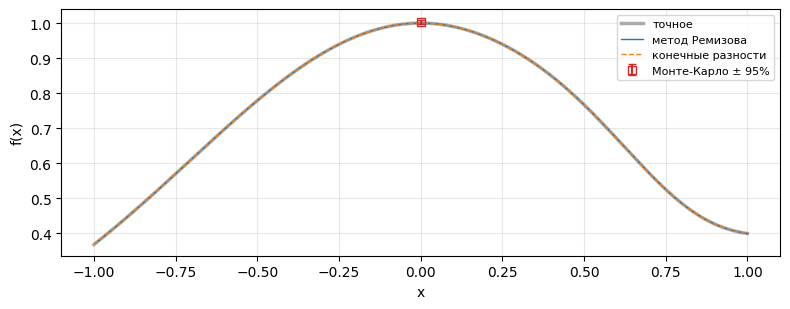

In [12]:
tc = tasks["glued_smooth"]
p = {'dx': 0.005, 'num_t': 201, 'eps': 1e-06, 'margin': 4.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## 10. `glued_kink`

Склейка только C^1 (значение и первая производная совпадают, вторая — нет) => g(x) терпит разрыв в x=0. Это ВНЕ гипотез теоремы (g требуется непрерывной), сознательный стресс-тест на устойчивость методов за пределами теории, а не верификационный тест. Хвост именно cos, а не sin: вклад слагаемого x^2*tail во вторую производную в нуле равен 2*tail(0), и для sin(6x) он обнуляется — склейка тогда получается C^2, разрыв уезжает в третью производную f, а g остаётся непрерывной (ровно этот дефект был у первой версии теста и найден при оценке норм в convergence.ipynb).

$$
a(x)=1,\qquad b(x)=0,\qquad c(x)=0,\qquad \lambda=2.
$$

$$
f_*(x)=\begin{cases} e^{- x^{2}} & \text{for}\: x \leq 0 \\\frac{\left(- x^{2} \cos{\left(6 x \right)} + 2\right) e^{- x^{2}}}{2} & \text{otherwise} \end{cases}.
$$


метод                 погрешность  время, с
метод Ремизова           3.16e-03      3.00
конечные разности        7.93e-04      0.00
Рунге–Кутта 4            2.62e-04      0.06
Розенброк 2              7.78e-04      0.07
Монте-Карло (x=0)        7.81e-04      6.93
Монте-Карло: f(0) ≈ 1.0008 ± 0.0062


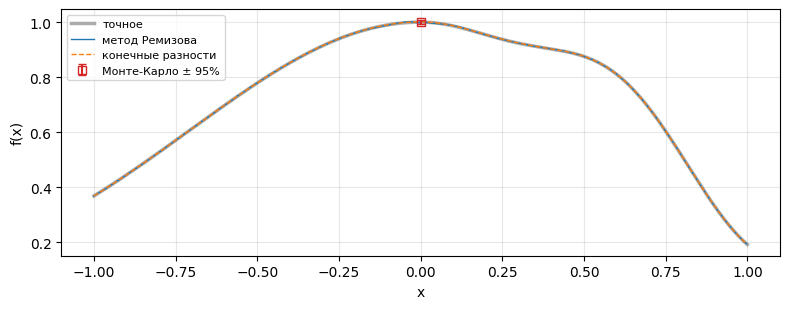

In [13]:
tc = tasks["glued_kink"]
p = {'dx': 0.0025, 'num_t': 101, 'eps': 0.001, 'margin': 4.0}

res, curves = {}, {}

t0 = time.perf_counter()
x, f = remizov(tc, p)
res["метод Ремизова"] = (sup_err(tc, x, f), time.perf_counter() - t0)
curves["метод Ремизова"] = (x, f)

for name, solver_class in (
    ("конечные разности", FiniteDifferenceSolver),
    ("Рунге–Кутта 4", RungeKuttaSolver),
    ("Розенброк 2", RosenbrockSolver),
):
    t0 = time.perf_counter()
    x, f = grid_method(solver_class, tc)
    res[name] = (sup_err(tc, x, f), time.perf_counter() - t0)
    curves[name] = (x, f)

t0 = time.perf_counter()
r = mc_solve(tc.a, tc.b, tc.c, tc.g, tc.lam, 0.0, M=MC_M, dt=MC_DT, seed=0)
mc_err = abs(r.value - float(tc.f_exact(np.array([0.0]))[0]))
res["Монте-Карло (x=0)"] = (mc_err, time.perf_counter() - t0)

RESULTS[tc.name] = res
show_results(tc, res, curves, r)

## Сводка

Погрешность $\sup_{[-1,1]}|f_{\text{числ}}-f|$ (для Монте-Карло — в точке $x=0$).

In [14]:
methods = list(next(iter(RESULTS.values())))
print(f"{'задача':24s}" + "".join(f"{m:>20s}" for m in methods))
for name, res in RESULTS.items():
    print(f"{name:24s}" + "".join(f"{res[m][0]:20.2e}" for m in methods))

задача                        метод Ремизова   конечные разности       Рунге–Кутта 4         Розенброк 2   Монте-Карло (x=0)
const_baseline                      1.83e-05            1.50e-05            7.85e-11            1.08e-05            7.50e-03
const_convection                    5.08e-06            1.80e-05            1.60e-10            9.90e-06            5.95e-03
var_smooth                          2.45e-05            1.69e-05            1.62e-10            1.14e-05            4.69e-03
var_pinch                           1.44e-04            2.78e-05            2.71e-10            1.42e-05            3.26e-03
stiff_const                         3.17e-05            3.51e-05            7.76e-08            5.69e-06            2.93e-04
stiff_variable                      6.83e-05            7.30e-05            1.60e-07            2.02e-05            1.64e-03
osc_highfreq_solution               1.83e-06            4.96e-04            3.30e-08            3.73e-04            1.84e-02
